In [1]:
%pip install sqlalchemy pymysql
!pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pymysql


# **Nivell 1 - Visualització analítica guiada en Python**

## **Exercici 1: Preguntes analítiques directes (sense integracions complexes)**

In [3]:
def cargar_tabla(usuario, contrasenya, host, base_datos, nombre_tabla):
    conexion = pymysql.connect(
        host=host,
        user=usuario,
        password=str(contrasenya),
        database=base_datos)

    df = pd.read_sql(f"SELECT * FROM {nombre_tabla}", con=conexion)
    conexion.close()
    return df

df_trans = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'transaction')

display(df_trans.head(3))

C:\Users\xavip\AppData\Local\Temp\ipykernel_8596\1472090711.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(f"SELECT * FROM {nombre_tabla}", con=conexion)


,id,card_id,business_id,user_id,timestamp,amount,declined,product_ids,lat,longitude,discount_amount,tax_amount,shipping_amount,channel,campaign_id,device_type,is_international,decline_reason,distance_km
0,00043A49-2949-494B-A5DD-A5BAE3BB19DD,CcS-9294,b-2458,4713,2024-08-28 07:16:46,433.51,0,"16, 26, 97, 87",46.199929,1.435540,34.17,72.25,0.0,online,SUMMER_TRAVEL,mobile,0,,59.95
1,00045D6B-ED2E-4F2F-8186-CEE074D875D0,CcS-6699,b-2390,2118,2020-07-14 15:37:45,332.38,0,"30, 11, 16, 81",29.757296,-95.379637,16.10,22.47,0.0,store,SUMMER_TRAVEL,pos,1,,1157.10
2,000481C3-1C26-4FEF-83A0-4CD0EB004BBD,CcS-6696,b-2230,2115,2017-09-04 19:44:53,175.00,0,72,53.548884,-113.503053,1.05,14.45,0.0,store,NO_CAMPAIGN,pos,0,,540.32


**- 1: Com evoluciona el nombre de transaccions al llarg del temps?**
Necessitem el nombre de transaccions i la data (df_trans) de la taula transaction. I de variable necessitem timestamp (datetime) i un count del recompte de transaccions agregat per mes. Es veu una tendencia de pujada en el número de transaccions al llarg dels anys.

<Axes: xlabel='month', ylabel='Nombre de transaccions'>

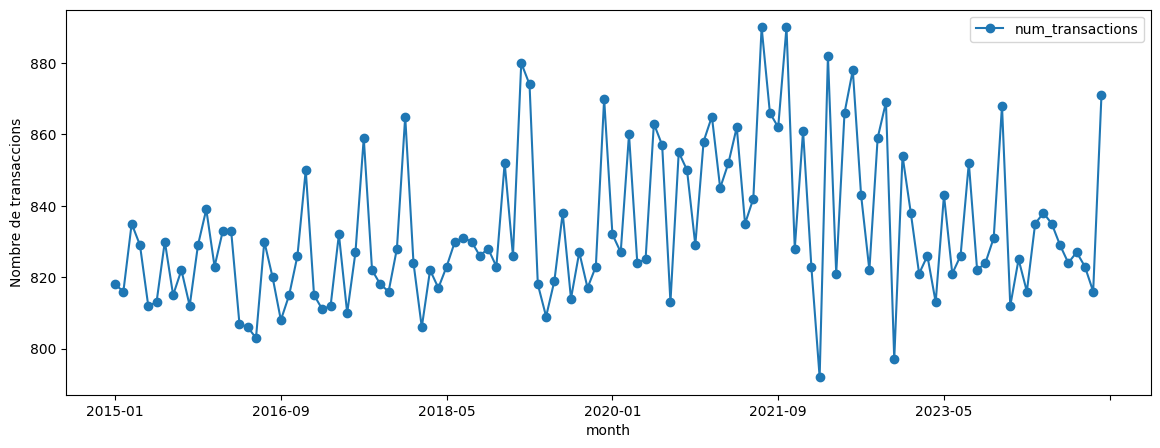

In [4]:
df = df_trans.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'])

df['month'] = df['timestamp'].dt.to_period('M')

tx_per_mes = (df.groupby('month')
                  .size()
                  .reset_index(name='num_transactions')
                  .sort_values('month'))

tx_per_mes['month'] = tx_per_mes['month'].astype(str)

# grafic
tx_per_mes.plot(
    x='month',
    y='num_transactions',
    kind='line',
    figsize=(14, 5),
    marker='o',
    ylabel='Nombre de transaccions')

**- 2: Quins usuaris generen més volum de facturació? Exemple de passos guiats amb seaborn:** S'identifica l'usuari i l'import de cada transacció amb la taula "transaction". Les variables són "user_id" i sum de "amount". Hi ha dos usuaris amb un import clarament superior als altres.

C:\Users\xavip\AppData\Local\Temp\ipykernel_8596\2076102012.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_usuaris,


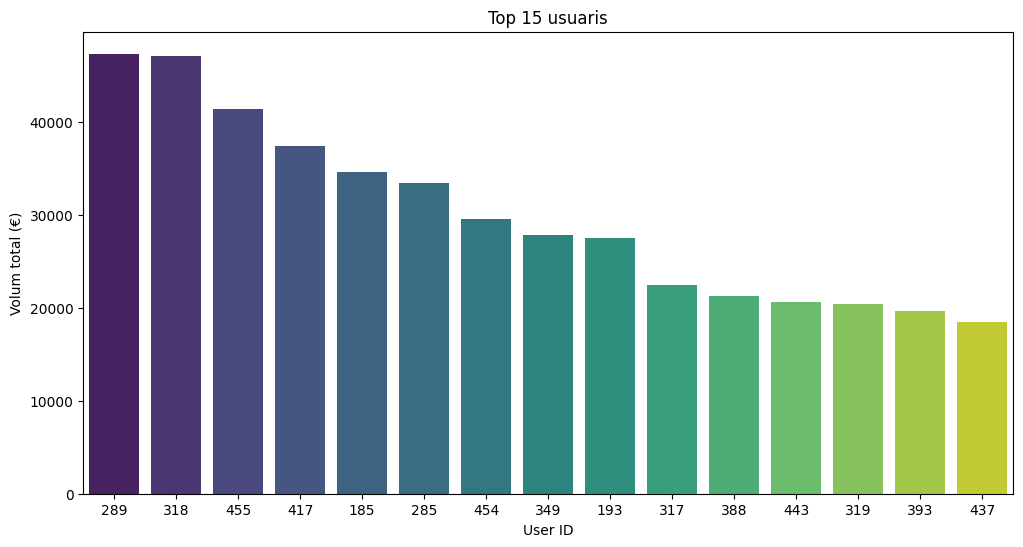

In [5]:
top_usuaris = (df_trans.groupby('user_id')['amount'].sum().reset_index(name='total_amount').sort_values('total_amount', ascending=False).head(15))

# gràfic

plt.figure(figsize=(12, 6))
sns.barplot(data=top_usuaris,
    x='user_id',
    y='total_amount',
    order=top_usuaris['user_id'],
    palette='viridis')

plt.title('Top 15 usuaris')
plt.xlabel('User ID')
plt.ylabel('Volum total (€)')
plt.show()

**- 3: Hi ha diferències en la distribució de l'import de les transaccions segons l'hora del dia i si han estat acceptades o rebutjades?:** Es crea una columna nova "hour" que guarda l'hora de cada transacció. Després es crea el gràfic no l'eix x mostra l'hora y l'y mostra l'import, i el color indica si la transacció ha estat rebutjada (1) o acceptada (0). Amb split=True es comparen i amb inner='quartile' es mostra mediana i quartils al gràfic.

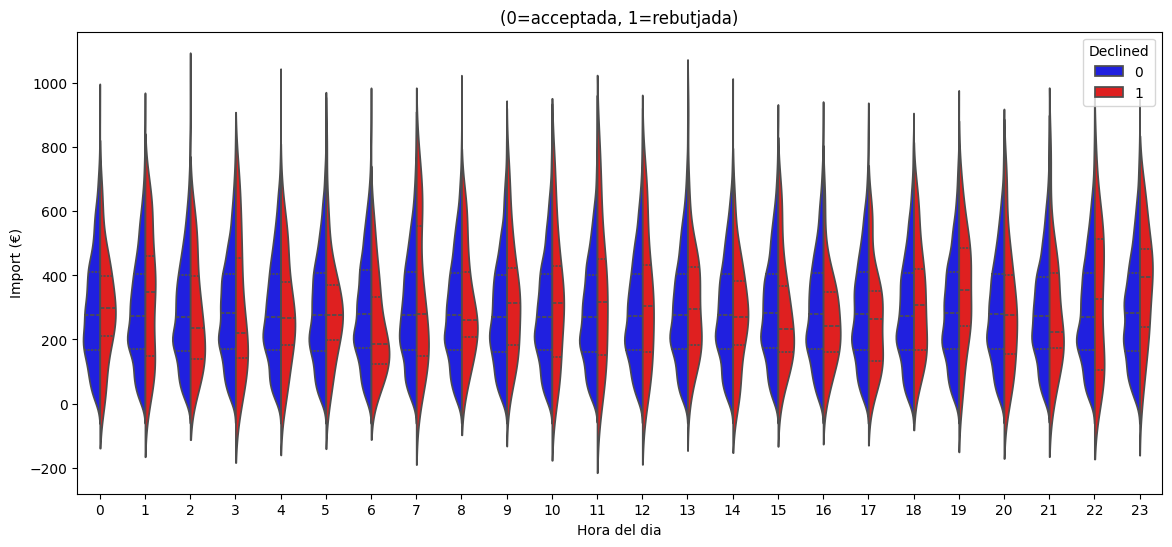

In [6]:
df['hour'] = df['timestamp'].dt.hour

plt.figure(figsize=(14, 6))
sns.violinplot(
    data=df,
    x='hour',
    y='amount',
    hue='declined',
    split=True,
    inner='quartile',
    palette={0: 'blue', 1: 'red'})

plt.title('(0=acceptada, 1=rebutjada)')
plt.xlabel('Hora del dia')
plt.ylabel('Import (€)')
plt.legend(title='Declined')
plt.show()

**- 4: Quins dies de la setmana es concentra més activitat de venda?**

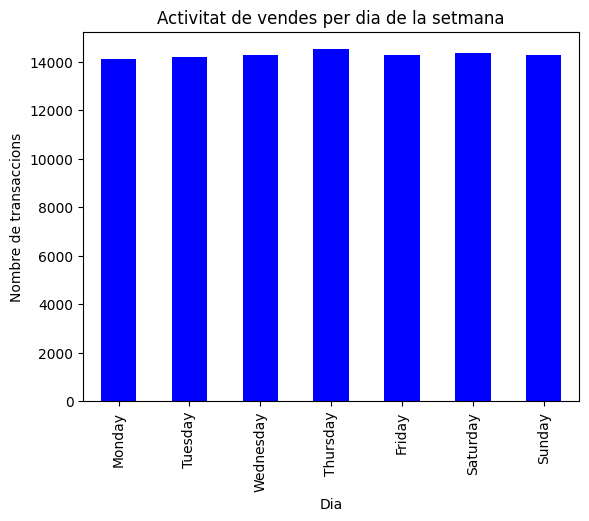

In [7]:
df = df_trans.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'])

df['dia'] = df['timestamp'].dt.day_name()

activitat = df['dia'].value_counts()

ordre = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
activitat = activitat.reindex(ordre)

# gràfic

activitat.plot(kind='bar', color='blue')
plt.title('Activitat de vendes per dia de la setmana')
plt.xlabel('Dia')
plt.ylabel('Nombre de transaccions')
plt.show()

## **Exercici 2: Preguntes analítiques complexes (amb guia)**

**- 1: Depenem excessivament d'un nombre reduït de països de companyies venedores?:** Es carrega la taula company, es combina les transaccions amb les companyies amb un merge de business_id = company_id. S'agrupa per país, es suma la fcturació i s'ordena de major a menor per facturació. Es veu que hi ha 5 paísos on l'empresa depen més de les vendes; Suecia, Holanda, UK, Italia i Alemanya.

C:\Users\xavip\AppData\Local\Temp\ipykernel_8596\1472090711.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(f"SELECT * FROM {nombre_tabla}", con=conexion)


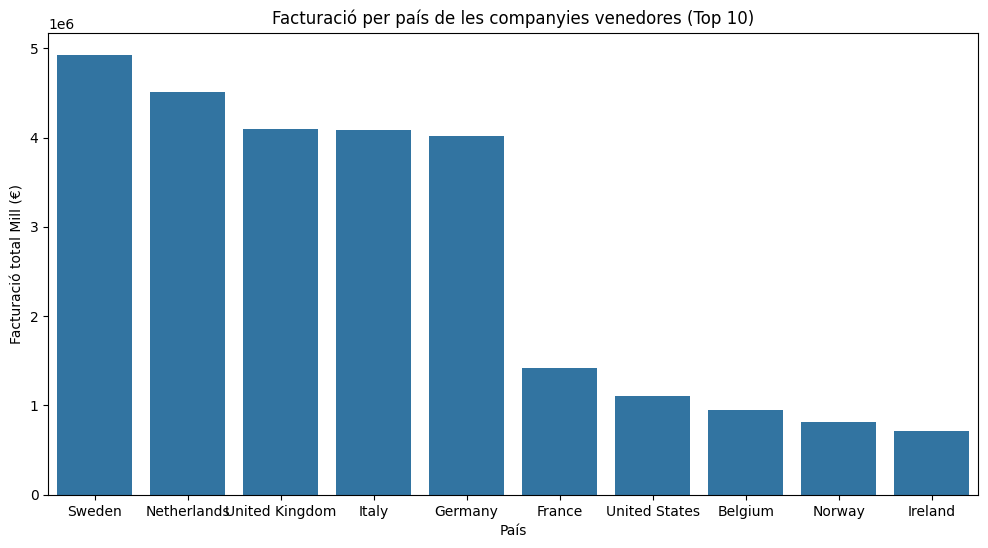

In [8]:
df_company = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'company')

df_merged = df_trans.merge(df_company, left_on='business_id', right_on='company_id')

facturacio_pais = (df_merged.groupby('country')['amount'].sum().reset_index(name='total').sort_values('total', ascending=False))

facturacio_pais['percentatge'] = facturacio_pais['total'] / facturacio_pais['total'].sum() * 100
facturacio_pais['percentatge_acumulat'] = facturacio_pais['percentatge'].cumsum()

# gràfic

plt.figure(figsize=(12, 6))
sns.barplot(data=facturacio_pais.head(10), x='country', y='total')
plt.title('Facturació per país de les companyies venedores (Top 10)')
plt.xlabel('País')
plt.ylabel('Facturació total Mill (€)')
plt.show()

**- 2: Existeix estacionalitat en les vendes?:** Es converteix la columna "timestamp" a format data. Extraem l'any i el mes de cada transacció i agrupem per any i mes i sumem el volum de vendes. Es crea una taula pivot amb els mesos a X, anys a Y. Es por observar com els mesos de març, maig i octubre són estacionalment millors en el sentit de vendes.  

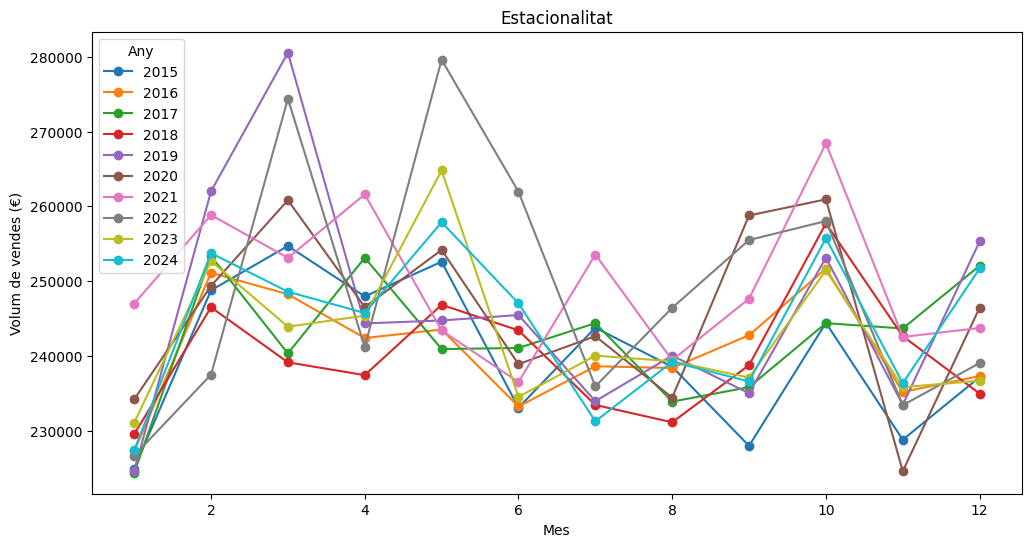

In [9]:
df = df_trans.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['any'] = df['timestamp'].dt.year
df['mes'] = df['timestamp'].dt.month

vendes = df.groupby(['any', 'mes'])['amount'].sum().reset_index()

pivot = vendes.pivot(index='mes', columns='any', values='amount')

# gràfic

pivot.plot(figsize=(12, 6), marker='o')
plt.title('Estacionalitat')
plt.xlabel('Mes')
plt.ylabel('Volum de vendes (€)')
plt.legend(title='Any')
plt.show()

**- 3: Anàlisi de concentració i variabilitat: Opció A – Producte:** Carreguem la taula de productes i la taula pont. Juntem les transaccions amb els productes mitjançant dos merge. Filtem només els 15 productes que generen més ingressos. Dibuixem un boxplot ordenat de major a menor ingressos per veure la variabilitat dels imports de cada producte. Es pot observar que els top 3 productes amb més facturació són "the duel", "Winterfell" i "skywalker ewok", la mitjana de gairebé tots el productes ronda els 300-400 euros d'import.

C:\Users\xavip\AppData\Local\Temp\ipykernel_8596\1472090711.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(f"SELECT * FROM {nombre_tabla}", con=conexion)


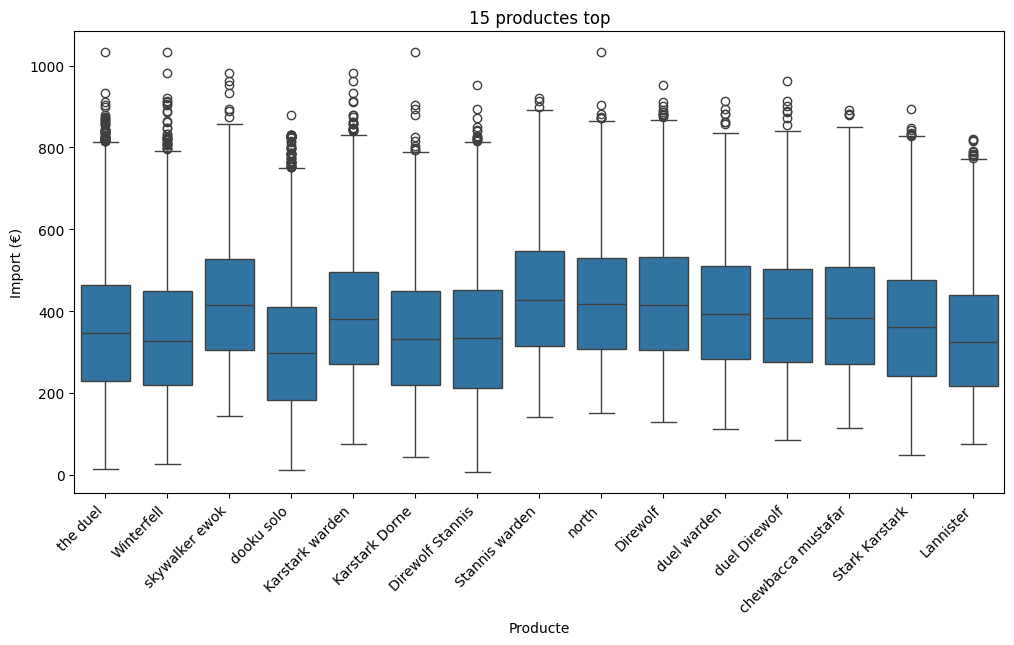

In [10]:
df_product = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'product')
df_tp = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'transaction_product')

df = df_trans.merge(df_tp, left_on='id', right_on='transaction_id')
df = df.merge(df_product, left_on='product_id', right_on='id')

top = (df.groupby('product_name')['amount'].sum().sort_values(ascending=False).head(15))

top_names = top.index.tolist()
df_top = df[df['product_name'].isin(top_names)]

# gràfic

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='product_name', y='amount', order=top_names)
plt.title('15 productes top')
plt.xlabel('Producte')
plt.ylabel('Import (€)')
plt.xticks(rotation=45, ha='right')
plt.show()

# Nivell 2 – Anàlisi relacional i patrons avançats

## Exercici 1: Anàlisi de productes i captació d'usuaris

Ordenem les dades per usuari i data, i marquem com a "es_nou_usuari" la primera transacció de cada persona. Agrupem per producte i calculem els ingressos totals, variabilitat, nombre de nous usuaris i nombre total de compradors.
Es calcula el percentatge de nous usuaris sobre el total de compradors.
Classifiquem cada producte en una tipologia: captador, recurrent, emergent o estancat. Dibuixem un scatter plot: on s'observa que els productes amb més ingressos són majoritàriament de tipus "recurrent", els clients que compren ja compraven abans. Els productes estancats, en taronja, tenen pocs ingressos i poca cptació de nous usuaris, aporten poc valor de creixement en les dues línes, clients y facturació. Sembla que el negoci creix més per els usuaris existents i recurrents que per nou clients a través de products molt bons, això pot suposar un perill pel futur del negoci si els clients recurrents deixen de comprar.

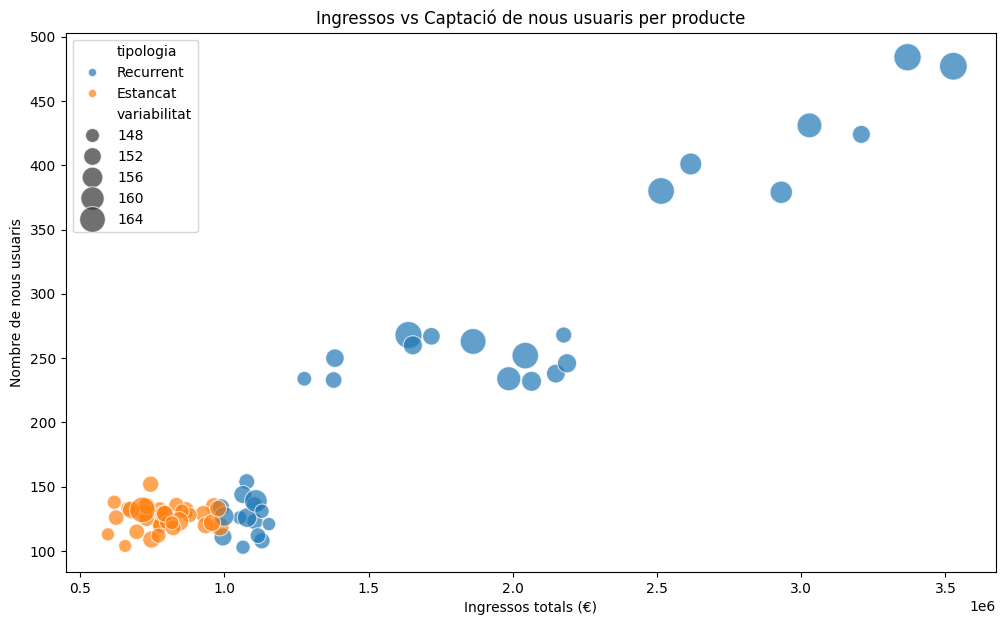

In [11]:
df = df.sort_values(['user_id', 'timestamp'])
df['es_nou_usuari'] = df.groupby('user_id')['timestamp'].transform('min') == df['timestamp']

resum = df.groupby('product_name').agg(ingressos_totals=('amount', 'sum'), variabilitat=('amount', 'std'), nous_usuaris=('es_nou_usuari', 'sum'), total_compradors=('user_id', 'nunique')).reset_index()

resum['pct_nous'] = resum['nous_usuaris'] / resum['total_compradors'] * 100

def tipologia(row):
    if row['pct_nous'] >= 40 and row['ingressos_totals'] >= resum['ingressos_totals'].median():
        return 'Captador'
    elif row['pct_nous'] < 40 and row['ingressos_totals'] >= resum['ingressos_totals'].median():
        return 'Recurrent'
    elif row['pct_nous'] >= 40 and row['ingressos_totals'] < resum['ingressos_totals'].median():
        return 'Emergent'
    else:
        return 'Estancat'

resum['tipologia'] = resum.apply(tipologia, axis=1)

# gràfic

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=resum,
    x='ingressos_totals',
    y='nous_usuaris',
    size='variabilitat',
    hue='tipologia',
    sizes=(50, 400),
    alpha=0.7)

plt.title('Ingressos vs Captació de nous usuaris per producte')
plt.xlabel('Ingressos totals (€)')
plt.ylabel('Nombre de nous usuaris')
plt.show()

## Exercici 2: Anàlisi geogràfica company–usuari i oportunitats d'expansió

Carreguem les taules "d'usuaris" i de "companyies", juntem les transaccions amb el país de l'usuari i el país de la companyia. Es crea la variable "compra_local": si el país de l'usuari i la companyia són del mateix país. Calculem el % global de transaccions i de facturament que són locals. S'agrupa per país de l'usuari i de país de companyia i calculem l'import total i el % de compres locals. Es crea el gràfic de brres amb el % de compres locals dels 10 països d’usuari amb més facturació.



*   En quins països valdria la pena obrir més companyies locals? Espanya Portugal i Polònia, amb molta demanda d'usuaris però un % de compres locals molt baix o nul.
*   Hi ha països amb demanda però poca oferta local? Sí, a Espanya, Portugal i Polònia; amb molta facturació però la totalitat de les compres es fan a companyies estrangeres.


*   El negoci depèn massa de companyies d’un sol país? No, la facturació està repartida entre diversos països, com Suècia, Holanda, UK, itàlia, etc. No es depèn únicament de uns pocs paisos, pero el negoci presenta una dependència de les vendes internacionals: el 88,1 % de la facturació prové de transaccions internacionals.

*   Obrir companyies locals reduiria fricció o milloraria la conversió? Es probable ya que només el 11,9% es facturació local, hi ha marge per captar usuaris que poder estar interessats en comprar en empreses locals. Es podría prioritzar estudios de mercat a Espanya, Portugal i Polònia.






C:\Users\xavip\AppData\Local\Temp\ipykernel_8596\1472090711.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(f"SELECT * FROM {nombre_tabla}", con=conexion)


% Transaccions locals: 11.9 %
% Facturació local: 11.9 %
% Transaccions internacionals: 88.1 %
% Facturació internacional: 88.1 %


,country_user,total_import,pct_local
10,United States,3091289.85,18.5
9,United Kingdom,2838889.37,17.3
7,Spain,2693566.24,1.7
0,Canada,2688940.83,9.7
4,Netherlands,2675165.65,19.3
6,Portugal,2638023.31,0.0
3,Italy,2603393.17,17.1
2,Germany,2573251.67,16.9
5,Poland,2512973.74,0.0
8,Sweden,2490810.72,21.3


,country_company,total_import,pct_local
12,Sweden,4928117.68,10.5
8,Netherlands,4506571.38,11.5
13,United Kingdom,4099117.08,12.1
7,Italy,4087557.38,10.7
5,Germany,4020364.07,11.1
4,France,1416084.26,11.4
14,United States,1101737.27,52.8
1,Belgium,952208.75,0.0
10,Norway,809288.82,0.0
6,Ireland,715220.46,0.0


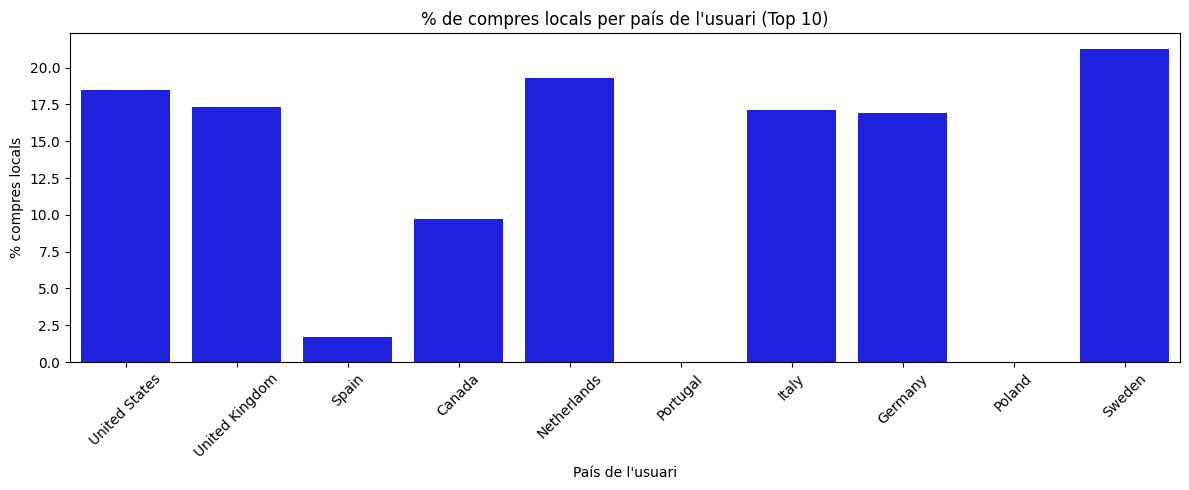

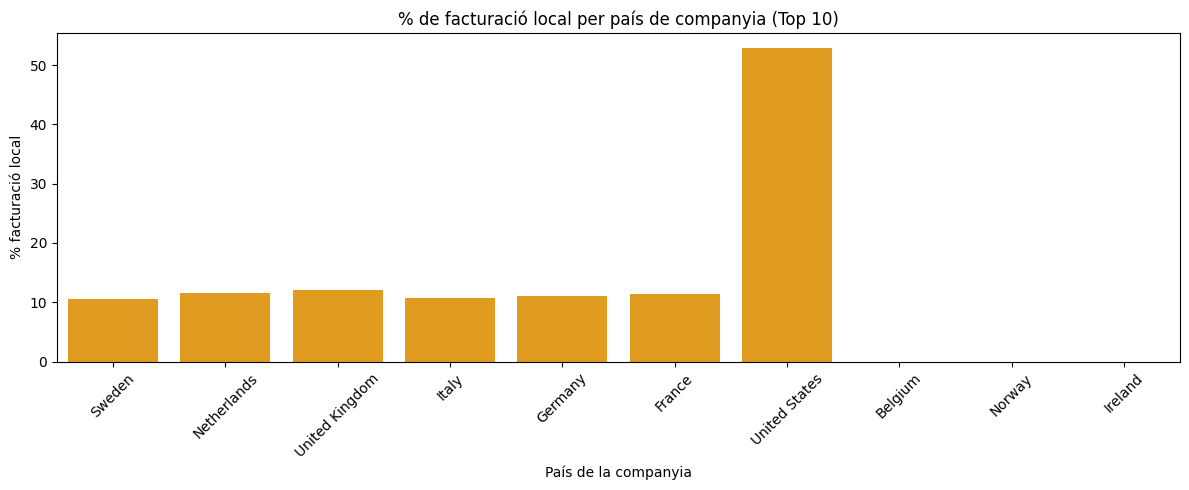

In [12]:
df_user = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'user')
df_company = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'company')

df = df_trans.merge(df_user[['id', 'country']], left_on='user_id', right_on='id', how='left')
df = df.merge(df_company[['company_id', 'country']], left_on='business_id', right_on='company_id', how='left',
              suffixes=('_user', '_company'))

df['compra_local'] = df['country_user'] == df['country_company']

print("% Transaccions locals:", round(df['compra_local'].mean()*100, 1), "%")
print("% Facturació local:", round(df.loc[df['compra_local'], 'amount'].sum() / df['amount'].sum()*100, 1), "%")
print("% Transaccions internacionals:", round((~df['compra_local']).mean() * 100, 1), "%")
print("% Facturació internacional:", round(df.loc[~df['compra_local'], 'amount'].sum() / df['amount'].sum() * 100, 1), "%")

per_usuari = (df.groupby('country_user').agg(total_import=('amount', 'sum'), pct_local=('compra_local', 'mean')).reset_index())
per_usuari['pct_local'] = (per_usuari['pct_local']*100).round(1)
per_usuari = per_usuari.sort_values('total_import', ascending=False)

display(per_usuari.head(10))


per_companyia = (df.groupby('country_company').agg(total_import=('amount', 'sum'), pct_local=('compra_local', 'mean')).reset_index())
per_companyia['pct_local'] = (per_companyia['pct_local']*100).round(1)
per_companyia = per_companyia.sort_values('total_import', ascending=False)

display(per_companyia.head(10))

# gràfic origen usuari

plt.figure(figsize=(12, 5))
sns.barplot(data=per_usuari.head(10), x='country_user', y='pct_local', color='blue')
plt.title('% de compres locals per país de l\'usuari (Top 10)')
plt.xlabel('País de l\'usuari')
plt.ylabel('% compres locals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# gràfic origen companyia

plt.figure(figsize=(12, 5))
sns.barplot(data=per_companyia.head(10), x='country_company', y='pct_local', color='orange')
plt.title('% de facturació local per país de companyia (Top 10)')
plt.xlabel('País de la companyia')
plt.ylabel('% facturació local')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Nivell 3 - Visualització executiva i storytelling

## Exercici 1: Mini-dashboard departamental

C:\Users\xavip\AppData\Local\Temp\ipykernel_8596\1472090711.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(f"SELECT * FROM {nombre_tabla}", con=conexion)


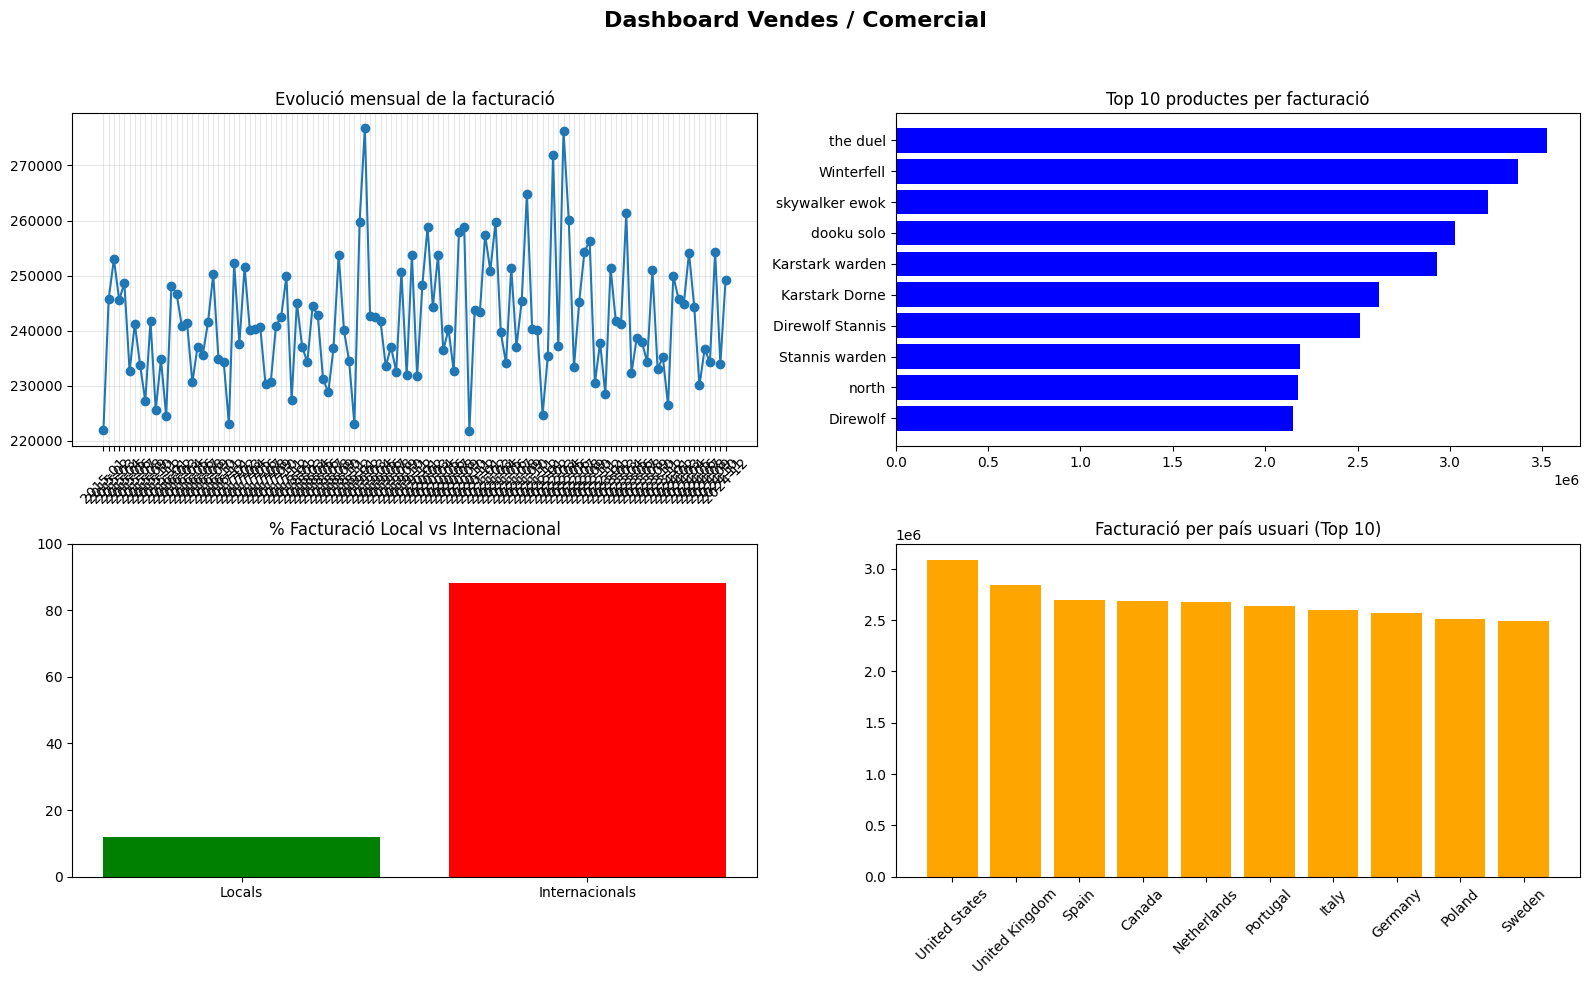

In [20]:
df_product = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'product')
df_tp = cargar_tabla('root', '1234', 'localhost', 'star_schema_db', 'transaction_product')

df_prod = df_trans.merge(df_tp, left_on='id', right_on='transaction_id')
df_prod = df_prod.merge(df_product, left_on='product_id', right_on='id')

# subplot

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Dashboard Vendes / Comercial', fontsize=16, fontweight='bold')

#Evolució mensual
df_temp = df_trans[df_trans['declined'] == 0].copy()
df_temp['timestamp'] = pd.to_datetime(df_temp['timestamp'])
df_temp['month'] = df_temp['timestamp'].dt.to_period('M').astype(str)
vendes_mes = df_temp.groupby('month')['amount'].sum()

axes[0,0].plot(vendes_mes.index, vendes_mes.values, marker='o', linewidth=1.5)
axes[0,0].set_title('Evolució mensual de la facturació')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].grid(True, alpha=0.3)

# top 10 productes
top_prod = (df_prod.groupby('product_name')['amount'].sum().sort_values(ascending=False).head(10))
axes[0,1].barh(top_prod.index[::-1], top_prod.values[::-1], color='blue')
axes[0,1].set_title('Top 10 productes per facturació')

# Local vs Internacional %
fact_local = df.loc[df['compra_local'] == True, 'amount'].sum()
pct_local = fact_local / df['amount'].sum() * 100

axes[1,0].bar(['Locals', 'Internacionals'], [pct_local, 100 - pct_local], color=['green', 'red'])
axes[1,0].set_title('% Facturació Local vs Internacional')
axes[1,0].set_ylim(0, 100)

# Facturació per país d'usuari
top_pais = per_usuari.sort_values('total_import', ascending=False).head(10)
axes[1,1].bar(top_pais['country_user'], top_pais['total_import'], color='orange')
axes[1,1].set_title('Facturació per país usuari (Top 10)')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Exercici 2: Informe executiu

- **Evolució de la facturació:** La facturació mensual del departament de vendes s’ha mantingut força estable, amb una lleugera tendència a l’alça i una certa estacionalitat. Habitualment, se situa entre els 230.000 € i els 250.000 €, amb mínims d’uns 222.000 € i màxims superiors als 270.000 €.

- **Facturació per producte:** «The Duel» és el producte estrella, amb més de 3.500.000 € de facturació, seguit de «Winterfell», amb 3.300.000 €. Tanmateix, els ingressos estan distribuïts de manera força homogènia entre diversos productes, fet que redueix la dependència d’un únic article i aporta resiliència al negoci.

- **Distribució geogràfica de les vendes:** Més del 80 % de la facturació prové de clients internacionals, fet que ofereix oportunitats d’expansió i d’obertura de nous mercats als paísos locals. No obstant això, aquesta dependència també comporta riscos davant l’augment de les polítiques proteccionistes.

- **Dependència de mercats estratègics:** Els EUA representen més de 3.000.000 € de facturació, de manera que les seves polítiques proteccionistes podrien afectar negativament el negoci a curt termini. A més, la dependència del Regne Unit, que no forma part de la UE, també implica riscos comercials i polítics. Tot i això, la presència en diversos mercats contribueix a diversificar els ingressos.


- **Correcció amb IA:**


1. Resum generalS’ha realitzat una anàlisi de la facturació del negoci des de quatre perspectives clau: evolució temporal, concentració per producte, pes del mercat local versus internacional i distribució geogràfica de la demanda. L’objectiu és proporcionar al departament comercial una visió clara de l’origen dels ingressos, identificar dependències estratègiques i detectar oportunitats de creixement.2. Troballes clau
La facturació mensual es manté estable, situant-se habitualment entre els 230.000 € i els 250.000 €, amb punts màxims superiors als 270.000 €. No s’observa una tendència de creixement sostingut, però tampoc un deteriorament.
«The Duel» lidera el ranking de productes amb més de 3,5 M€ de facturació, seguit de «Winterfell» (aprox. 3,3 M€). Tot i la concentració en els primers productes, la facturació està raonablement distribuïda entre diversos referents.
Més del 80 % de la facturació prové de clients internacionals. El negoci és clarament exportador.
Estats Units i Regne Unit són els dos mercats d’usuaris amb major volum de compra (més de 3 M€ i 2,8 M€ respectivament).

3. Riscos detectats
Alta exposició internacional: gairebé el 88 % de la facturació depèn de clients estrangers, la qual cosa genera vulnerabilitat davant de canvis en aranzels, regulacions o tipus de canvi.
Dependència de mercats clau fora de la UE: Estats Units i Regne Unit concentren una part significativa dels ingressos i estan subjectes a polítiques comercials pròpies.
Baixa penetració local en països amb demanda elevada (Espanya, Portugal i Polònia), on el percentatge de compres a companyies locals és pràcticament nul.

4. Oportunitats
Expansió de la presència local als països amb alta demanda i baixa oferta pròpia (Espanya, Portugal i Polònia).
Aprofitament de l’estabilitat de la facturació mensual per millorar la planificació comercial i de stock.
Desenvolupament d’estratègies de cross-selling i fidelització al voltant dels productes estrella («The Duel», «Winterfell», etc.).

5. Recomanacions
Prioritzar l’obertura o el reforç de companyies locals a Espanya, Portugal i Polònia per capturar demanda actualment atesa per competidors internacionals.
Implementar un seguiment mensual de la concentració de productes i de l’evolució dels mercats Estats Units i Regne Unit.
Dissenyar campanyes de fidelització i ofertes combinades centrades en els productes de major rotació per consolidar la base de clients recurrents.
Valorar l’impacte de possibles mesures proteccionistes als mercats exteriors i preparar plans de contingència comercial.
